# Week 6 — Decision trees and random forests
**Kumar Gaurav · DX799 O1 Data Science Capstone · Milestone One notebook appendix**

For Week 6, include concepts such as decision trees and random forests.

**Question:** can tree-based models, which learn if/then thresholds and interactions automatically, beat the ~0.71 (Lending Club)
and ~0.74 (Taiwan) ROC-AUC ceiling that logistic regression and SVMs reached in Weeks 4–5? Random Forest is one of the two
**depth models** of the Milestone One report, so it gets the most thorough tuning and diagnostics here.

## Part A — Data quality evaluation (done before any modeling)
Before fitting any model we check the data the way a careful analyst would by hand: what is in the file, what is missing,
what is duplicated, which values are impossible, which columns would leak the answer, and what the target looks like.
Every issue found is written into a **data-quality summary table** (issue, rows affected, action) so a reader can judge
how much the cleaning could have influenced the results. The same block appears in every weekly notebook so each one runs on its own.

**Datasets (one framing: consumer credit default risk)**
* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, target = default in October 2005.

## Cell 1 — Imports and loading the Lending Club audit columns
### Why are we doing this?
Everything later depends on the raw data being read correctly. We load only the ~28 columns we will audit or model instead
of all 145, because the full file is ~2.26M rows and loading everything wastes memory.
### What are we doing?
* `pandas` (`pd`) holds tables, `numpy` (`np`) does math, `matplotlib`/`seaborn` draw charts, `kagglehub` downloads/caches the Kaggle dataset.
* `pd.read_csv(..., usecols=LC_COLS)` reads only the listed columns. Four *post-outcome* columns (`total_pymnt`, `recoveries`, `last_pymnt_amnt`, `out_prncp`) are loaded **only** so we can prove later that they leak the answer and must be removed.
* `SEED = 42` fixes all random sampling so the notebook is reproducible (the seed makes results repeatable, not "correct").
### Alternatives
Reading all columns (simpler but ~5× the memory) or using a database/parquet copy (faster for repeated runs).
### What should we examine after execution?
The shape (rows × columns), the mix of data types (numbers vs text), and whether the first rows look sensible.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


## Result Interpretation — Lending Club load
### What did we actually get?
**2,260,668 rows × 28 audited columns**: 16 float, 9 text (`str`), 3 integer columns. In the first three rows, `id` shows `NaN`, the numbers look plausible (loan amounts 2,500–30,000; rates 13.56–18.94%), and `term` has a leading space (`" 36 months"`).
### What does it mean?
The file loaded correctly. Two things need attention right away: the identifier is empty, and text columns need parsing (`term`). These first rows are *current* loans, which is why `out_prncp` (outstanding principal) is non-zero. That previews the censoring problem handled two cells below.
### What should we do next?
Audit missingness across all 145 columns before choosing which ones to trust.

## Cell 2 — Null-column audit across the full 145-column file
### Why are we doing this?
Missing data silently shrinks or biases a sample. Columns that are mostly empty cannot be used, and columns that are
100% empty are useless (including identifiers we might have wanted for duplicate checks).
### How does it work?
The file is read in chunks of 500,000 rows; for each chunk `isnull().sum()` counts missing cells per column, and the counts
are added up. Dividing by the total rows gives the **missing %** per column. Chunking keeps memory low.
### Key concept — missingness
**Missing completely at random** (safe to drop) vs **missing not at random** (dropping can bias results, e.g. income missing
more often for riskier borrowers). With very small missing % the choice barely matters; with large % it matters a lot.
### What should we examine after execution?
How many columns are fully empty, how many exceed 50% missing, and the missing % of the columns we actually model.

In [2]:
# Null audit on the FULL 145-column header (chunked so memory stays small)
null_cnt, n_rows = None, 0
for ch in pd.read_csv(LC_PATH, chunksize=500_000, low_memory=False):
    c = ch.isnull().sum(); null_cnt = c if null_cnt is None else null_cnt + c; n_rows += len(ch)
null_pct = (null_cnt / n_rows * 100).sort_values(ascending=False)
print(f"All columns: {len(null_pct)} | rows: {n_rows:,}")
print(f"Columns 100% empty: {(null_pct == 100).sum()} -> {null_pct[null_pct == 100].index.tolist()}")
print(f"Columns > 50% missing (dropped from consideration): {(null_pct > 50).sum()}")
print("\nMissing % for the columns we use:")
use_pct = null_pct.reindex([c for c in LC_COLS if c != "id"]).round(3)
print(use_pct[use_pct > 0].to_string())

All columns: 145 | rows: 2,260,668
Columns 100% empty: 3 -> ['id', 'url', 'member_id']
Columns > 50% missing (dropped from consideration): 44

Missing % for the columns we use:
emp_length              6.498
dti                     0.076
delinq_2yrs             0.001
inq_last_6mths          0.001
open_acc                0.001
pub_rec                 0.001
revol_util              0.080
total_acc               0.001
mort_acc                2.213
pub_rec_bankruptcies    0.060


## Result Interpretation — Null-column audit
### What did we actually get?
* **3 of 145 columns are 100% empty:** `id`, `url`, `member_id`.
* **44 columns are more than 50% missing.** These are mostly hardship/settlement and joint-applicant fields that only exist for some loans. None of them are used.
* Among the columns we use, missingness is small: `emp_length` 6.50%, `mort_acc` 2.21%, `revol_util` 0.080%, `dti` 0.076%, `pub_rec_bankruptcies` 0.060%, and the rest 0.001%.
### What does it mean?
* Missingness in our model columns is low enough that dropping incomplete rows loses only a few percent. Most of that comes from `mort_acc`.
* `emp_length` (6.5% missing) is excluded from the models because its missingness may not be random. Borrowers who leave it blank may differ in risk.
* The empty `id` means duplicates must be detected by comparing whole rows.
### What can we NOT conclude?
That the dropped rows are like the kept rows. With about 2% of rows dropped, any bias is likely small, but it is not tested.

## Cell 3 — Closed loans, duplicates, invalid ranges, constants, cardinality and leakage
### Why are we doing this?
A model learns whatever is in the data — including errors. This cell applies explicit, documented decisions:
* **Outcome definition:** only closed loans (`Fully Paid`, `Charged Off`, `Default`) have a known outcome. `Current`/`Late` loans are censored, so including them would mislabel future defaults as "repaid".
* **Duplicates:** `id` is empty in this Kaggle copy, so we check exact duplicate rows instead.
* **Impossible values:** `dti` (debt-to-income) below 0 or the sentinel 999; income of 0 (cannot take a log or ratio).
* **Extreme but possible values:** `revol_util` above 100% means the borrower is over their credit limit — real, so we clip rather than drop.
* **Rare categories:** `home_ownership` ANY/NONE are merged into OTHER so one-hot encoding does not create near-empty columns.
* **Constant columns** carry no information.
* **Leakage screen:** a column known only *after* the outcome (e.g., total payments received, recoveries) would make the model look brilliant on paper and useless in practice. We print its mean by outcome to show the leak, then drop it.
### Alternatives
Imputing missing values (median or model-based) instead of dropping; winsorizing at percentiles instead of fixed caps.
With <1% of rows affected, listwise dropping is simpler and easier to defend.
### What should we examine after execution?
How many loans are closed, how many rows each check affects, and how strongly the leakage columns separate the outcomes.

In [3]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


## Result Interpretation — Cleaning decisions
### What did we actually get?
* **Outcomes:** 1,041,952 Fully Paid, 261,655 Charged Off and 31 Default form the **1,303,638 closed loans**. The 919,695 `Current` loans and the late or grace-period loans are excluded.
* **Constant column:** `policy_code` (always 1), dropped.
* **Cardinality:** `sub_grade` has 35 levels and `purpose` has 14. Both are manageable for one-hot encoding.
* **Leakage proof:** repaid loans average **$16,439** in `total_pymnt` and **$0** in `recoveries`. Defaulted loans average **$8,228** and **$1,174**. Recoveries are non-zero *only* after a default, so a model given this column would find the answer by reading the outcome. That is why it is dropped.
* **Final:** **1,254,818 clean closed loans**, with a **20.28%** default rate.
### What does it mean?
The outcome definition and the leakage screen matter most. Including `Current` loans would label future defaults as repaid, and including recoveries would give near-perfect but meaningless accuracy.

## Cell 4 — Lending Club data-quality summary, distributions and target balance
### Why are we doing this?
The summary table is the audit trail. The `describe()` table and histograms show skew and outliers, and the class balance
tells us which metrics are honest (with ~20% defaults, "predict everyone repays" already scores ~80% accuracy).
### What should we examine after execution?
Rows affected per issue (as a share of the total), mean vs median gaps (skew), the default share, and the skew of income before/after `log1p`.

,issue,rows_affected,action
0,Open/censored loan_status,957030,dropped (outcome unknown)
1,id column 100% null,0,cannot dedupe on id; deduped on full row instead
2,Exact duplicate rows,0,dropped
3,dti < 0 or > 100% (sentinel 999 / data error),478,set to NaN then dropped
4,revol_util > 100%,4537,clipped to 150 (over-limit is real but extreme)
5,annual_inc <= 0,302,dropped (cannot log/ratio)
6,annual_inc > $1M,279,kept; modeled as log1p(annual_inc)
7,home_ownership ANY/NONE/OTHER,459,merged into OTHER
8,Constant columns ['policy_code'],0,column dropped (no information)
9,"Post-outcome columns total_pymnt, recoveries, ...",0,columns dropped (target leakage)


,count,mean,std,min,25%,50%,75%,max
loan_amnt,1254818.0,14521.03,8716.03,1000.00,8000.00,12000.00,20000.00,40000.00
int_rate,1254818.0,13.30,4.79,5.31,9.75,12.79,16.02,30.99
annual_inc,1254818.0,76459.53,70288.00,430.00,46000.00,65000.00,90000.00,10999200.00
dti,1254818.0,18.35,8.67,0.00,11.95,17.78,24.26,100.00
revol_util,1254818.0,51.98,24.34,0.00,33.80,52.30,70.70,150.00
open_acc,1254818.0,11.68,5.48,1.00,8.00,11.00,14.00,90.00


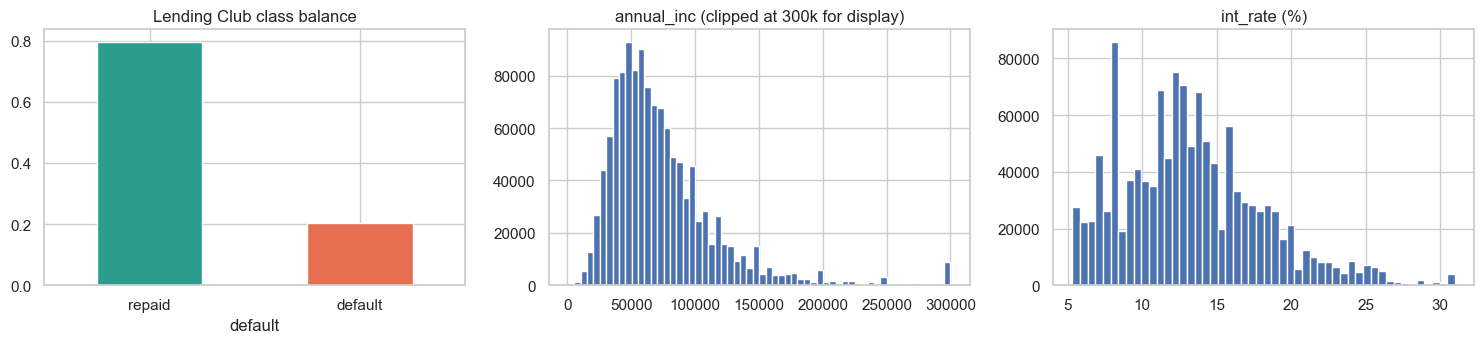

Skew annual_inc raw vs log1p: 47.64 -> 0.21


In [4]:
lc_dq = pd.DataFrame(dq, columns=["issue", "rows_affected", "action"])
display(lc_dq)
display(lc[["loan_amnt", "int_rate", "annual_inc", "dti", "revol_util", "open_acc"]].describe().round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
lc["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Lending Club class balance"); ax[0].set_xticklabels(["repaid", "default"], rotation=0)
ax[1].hist(lc["annual_inc"].clip(upper=300000), bins=60); ax[1].set_title("annual_inc (clipped at 300k for display)")
ax[2].hist(lc["int_rate"], bins=50); ax[2].set_title("int_rate (%)")
plt.tight_layout(); plt.show()
print("Skew annual_inc raw vs log1p:", round(lc["annual_inc"].skew(), 2), "->", round(lc["log_annual_inc"].skew(), 2))

## Result Interpretation — Lending Club data-quality summary
### What did we actually get?
| Issue | Rows affected | Share of closed loans |
|---|---|---|
| Open or censored status | 957,030 | (dropped before the closed count) |
| `dti` < 0 or > 100 | 478 | 0.04% |
| `revol_util` > 100% | 4,537 | 0.35% (clipped at 150) |
| `annual_inc` ≤ 0 | 302 | 0.02% |
| `annual_inc` > $1M | 279 | kept, log-transformed |
| home_ownership ANY/NONE/OTHER | 459 | merged |
| Remaining NaNs | 48,518 | 3.7% (mostly `mort_acc`) |

Exact duplicate rows: **0**. After cleaning: `int_rate` mean 13.30% with SD 4.79, range 5.31–30.99. `dti` now runs 0–100.
* **Skew:** `annual_inc` has mean $76,437 vs median $65,000, a max of $10,999,200, and **skew 47.63, which falls to 0.18 after `log1p`**.
* **Charts:** the class-balance chart shows about 80/20 repaid vs default.
### What does it mean?
* **Income must be logged.** Without the log, a few millionaires would dominate any linear model.
* **Accuracy is a weak metric here.** An "everyone repays" rule already scores about 80%, so later weeks judge models by ROC-AUC, F1 and recall.
* **Cleaning removed about 4% of closed loans,** mostly rows with an incomplete credit history.
### What should we do next?
Run the same audit on the Taiwan dataset.

## Cell 5 — Loading the Taiwan credit-card default data
### Why are we doing this?
This is the second dataset. It is a different market (revolving credit cards, Taiwan 2005) with the same question —
who will default — so it lets us check whether conclusions generalize beyond Lending Club.
### What are we doing?
Downloading/caching via `kagglehub` and reading the single CSV. Columns: `LIMIT_BAL` (credit limit, NT$), `SEX`, `EDUCATION`,
`MARRIAGE`, `AGE`, `PAY_0, PAY_2..PAY_6` (repayment status by month, −1 = paid on time, 1..9 = months late),
`BILL_AMT1-6` (statement balances), `PAY_AMT1-6` (amounts paid), and the target `default.payment.next.month`.
### What should we examine after execution?
Shape, data types, and whether the first rows match the documented coding.

In [5]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


## Result Interpretation — Taiwan load
### What did we actually get?
**30,000 rows × 25 columns**: 13 float and 12 integer, with no text columns. Row 1 has `PAY_0 = 2` (two months late) and target = 1 (defaulted). That is an early hint that repayment status carries a strong signal.
### What should we do next?
Check the documented and undocumented category codes.

## Cell 6 — Taiwan nulls, duplicates, undocumented codes, ranges and leakage
### Why are we doing this?
This dataset is famous for **undocumented category codes** (EDUCATION 0/5/6, MARRIAGE 0, PAY = −2). If we left them as-is,
a model would treat them as meaningful groups. We also check duplicates, negative bills, and leakage.
### How does it work?
* Rename `PAY_0` to `PAY_1` so the six months are numbered consistently, and the long target name to `default`.
* Duplicates are checked ignoring `ID` (different IDs with identical 23 features are almost certainly repeated records).
* Undocumented codes are merged into the documented "other" category.
* `PAY_*` is kept **ordinal numeric** (−2 < −1 < 0 < 1 … months late) because the order carries risk information.
* Negative bills (customer overpaid) are real, so we use a **signed log** `sign(x)·log(1+|x|)` that tames skew while keeping the sign.
### What should we examine after execution?
Counts per code, how many rows each issue touches, and the final row count and default rate.

In [6]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Result Interpretation — Taiwan checks
### What did we actually get?
* **Missing values:** 0 null cells, and no duplicate IDs.
* **Duplicates:** **35 duplicate profiles** when ID is ignored. They were dropped.
* **Undocumented codes:**
  * `EDUCATION`: 0 (14 rows), 5 (280) and 6 (51), 345 in total.
  * `MARRIAGE`: 0 (54 rows).
  * `PAY_1`: −2 (2,750 rows) plus a long tail of codes 3–8 that are rare (322 or fewer rows each).
* **Final:** **29,965 rows**, with a **22.13%** default rate.
### What does it mean?
The undocumented codes affect about 1.3% of rows for EDUCATION and MARRIAGE, so merging them into "other" is low-risk. `PAY_* = −2` is common (6,531 clients have it in some month), which is too many to drop. It is best treated as "no balance to pay", ranked below "paid duly".

## Cell 7 — Taiwan data-quality summary, collinearity preview and target balance
### Why are we doing this?
The table documents decisions; the heatmap previews **multicollinearity** among the six monthly bills (which decides whether
regularization/PCR will matter); the default rate by `PAY_1` previews the strongest risk signal.
### What should we examine after execution?
Bill correlations (values near 1 mean near-duplicate predictors), the default-rate gradient across `PAY_1` codes, and skew of `LIMIT_BAL`.

,issue,rows_affected,action
0,Missing values,0,none to handle
1,Duplicate ID,0,none
2,Duplicate rows (ignoring ID),35,dropped (identical profiles)
3,EDUCATION undocumented codes 0/5/6,345,recoded to 4 = other
4,MARRIAGE undocumented code 0,54,recoded to 3 = other
5,"PAY_* = -2 (no consumption, undocumented)",6531,kept as ordinal (-2 < -1 paid duly < 0 revolving)
6,Negative BILL_AMT (credit balance/overpay),1930,kept; signed log transform
7,AGE range 21-79,0,"plausible, kept"
8,Constant columns,0,none
9,Post-outcome columns,0,none: all features precede target month


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,29965.0,167442.0,129760.1,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,29965.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
BILL_AMT1,29965.0,51283.0,73658.1,-165580.0,3595.0,22438.0,67260.0,964511.0
PAY_AMT1,29965.0,5670.1,16571.8,0.0,1000.0,2102.0,5008.0,873552.0
PAY_1,29965.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0


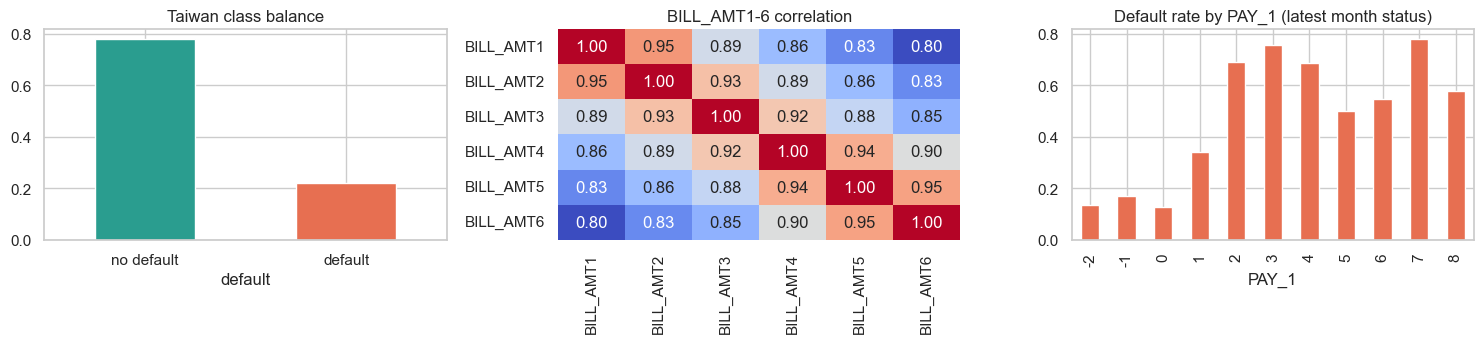

Skew LIMIT_BAL raw vs log: 0.99 -> -0.51


In [7]:
tw_dq = pd.DataFrame(tdq, columns=["issue", "rows_affected", "action"])
display(tw_dq)
display(tw[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "PAY_1"]].describe().round(1).T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tw["default"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#2a9d8f", "#e76f51"])
ax[0].set_title("Taiwan class balance"); ax[0].set_xticklabels(["no default", "default"], rotation=0)
sns.heatmap(tw[BILL].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], cbar=False)
ax[1].set_title("BILL_AMT1-6 correlation")
tw.groupby("PAY_1")["default"].mean().plot.bar(ax=ax[2], color="#e76f51"); ax[2].set_title("Default rate by PAY_1 (latest month status)")
plt.tight_layout(); plt.show()
print("Skew LIMIT_BAL raw vs log:", round(tw["LIMIT_BAL"].skew(), 2), "->", round(tw["log_LIMIT_BAL"].skew(), 2))

## Result Interpretation — Taiwan data-quality summary
### What did we actually get?
* **Issues table:** 35 duplicates, 345 education recodes, 54 marriage recodes, 6,531 rows with a −2 code, 1,930 rows with a negative bill, ages 21–79, and no leakage columns.
* **Bill correlations:** `BILL_AMT1–6` are strongly correlated. Neighbouring months are near 0.95, and month 1 vs month 6 is about 0.80.
* **Default rate by `PAY_1`:** about 13–17% for codes −2, −1 and 0 (no balance, paid duly, revolving). It rises to **34%** for 1 month late and **69%** for 2 months late, and stays at 50–78% for the rare longer delays.
* **Skew of `LIMIT_BAL`:** 0.99 raw, −0.51 after log.
### What does it mean?
* **Multicollinearity is high here, unlike Lending Club.** Regularization (Week 2) and PCR/PLS (Week 3) should matter much more on this dataset.
* **`PAY_1` is the dominant risk signal.** Any later model that does not rank it highly deserves suspicion.
* **About 22% default,** a similar imbalance to Lending Club, so the same metrics apply.
### What should we do next?
Move to the modeling for this week (Part B).

## Part B — Trees and forests
### Key concepts (read before the code)
* **Decision tree:** repeatedly splits the data on the single feature/threshold that most reduces **impurity** (Gini = 1 − Σpₖ²; 0 for a pure node). Prediction = share of defaults in the leaf. Trees need no scaling and capture thresholds and interactions natively, but a deep tree memorizes the training data (high variance).
* **Controlling tree overfitting:** limit `max_depth`, require `min_samples_leaf`, or grow the full tree and **prune** it with cost-complexity pruning (`ccp_alpha`: a split is kept only if it reduces impurity by more than α per extra leaf).
* **Random forest:** averages hundreds of deep trees, each grown on a **bootstrap sample** (rows drawn with replacement) and allowed to consider only a random subset of features (`max_features`) at each split. Averaging many de-correlated noisy trees cancels much of their variance (bagging + feature randomness).
* **Out-of-bag (OOB) score:** each tree never sees about 37% of the rows (those left out of its bootstrap sample); predicting those rows gives a built-in validation estimate without a separate holdout.

## Cell 8 — Shared classification setup (identical in Weeks 4, 5 and 6)
### Why are we doing this?
To compare logistic regression, SVM, decision trees and random forests fairly, every week must use the **same rows, the same
features and the same test set**. This cell defines them once; Weeks 5 and 6 contain an identical copy.
### What are we doing?
* **Lending Club:** a 60,000-loan random sample of the clean closed loans (seed 42), split 80/20 **stratified** on `default`, so both parts keep the about 20% default rate.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.
* `make_prep(num, cat, scale=True)` returns a `ColumnTransformer`. Numerics are standardized and categoricals one-hot encoded. It is always fit inside a pipeline on training folds only, so no test-set leakage.
### Key concept — stratification
With 20–22% positives, a random split could, by chance, put noticeably more defaults in one part. Stratifying guarantees equal rates, which makes metrics comparable between train and test.
### What should we examine after execution?
Train/test sizes and that the default rates match between splits.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["log_LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2, stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2, stratify=tw["default"], random_state=SEED)
DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan": (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%} | numeric {len(num)}, categorical {len(cat)}")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import time

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


## Result Interpretation — Shared classification setup
### What did we actually get?
* **Lending Club:** train 48,000 × 11 and test 12,000 × 11. Both have a **20.29%** default rate, with 6 numeric and 5 categorical features.
* **Taiwan:** train 23,972 × 23 and test 5,993 × 23. Both are at **22.13%** default, with 20 numeric and 3 categorical features.
### What does it mean?
* **Stratification worked.** The default rates are identical across splits, so every later metric is comparable between train and test, and across weeks.
* **Baselines to beat:**
  * Accuracy: an "everyone repays" rule scores **79.7%** on Lending Club and **77.9%** on Taiwan.
  * PR-AUC: a random ranking scores **0.203** and **0.221**.

## Cell 9 — Decision tree: `max_depth` sweep (train vs 5-fold CV AUC)
### Why are we doing this?
`max_depth` is the most direct complexity control. Plotting training and validation AUC against depth shows the
**bias–variance trade-off**. Shallow trees underfit (both scores low); deep trees overfit (training AUC → 1, validation falls).
### How does it work?
For depth 1–20 and unlimited, a 5-fold stratified CV computes mean train and validation AUC. `class_weight="balanced"` matches
Weeks 4–5. Trees do not need scaling, but the same preprocessor is used (scaling is harmless for trees) to keep pipelines identical.
### What should we examine after execution?
The depth with the best validation AUC, the gap at that depth, and the gap for an unlimited tree.

In [9]:
from sklearn.model_selection import cross_validate
depths = list(range(1, 21)) + [None]
dt_curves = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    res = []
    for d_ in depths:
        pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", DecisionTreeClassifier(max_depth=d_, class_weight="balanced", random_state=SEED))])
        cv = cross_validate(pipe, Xa, ya, cv=CV5, scoring="roc_auc", return_train_score=True, n_jobs=-1)
        res.append((d_ if d_ else 40, cv["train_score"].mean(), cv["test_score"].mean(), cv["test_score"].std()))
    dt_curves[name] = pd.DataFrame(res, columns=["max_depth", "train_auc", "cv_auc", "cv_sd"])
    b = dt_curves[name].loc[dt_curves[name].cv_auc.idxmax()]
    full = dt_curves[name].iloc[-1]
    print(f"{name}: best depth={int(b.max_depth)} CV AUC={b.cv_auc:.4f} +- {b.cv_sd:.4f} (train {b.train_auc:.4f}) | "
          f"unlimited depth: train {full.train_auc:.4f} vs CV {full.cv_auc:.4f}")
    display(dt_curves[name].iloc[[0, 2, 4, 6, 8, 11, 14, 19, 20]].round(4).T)

Lending Club: best depth=5 CV AUC=0.6898 +- 0.0044 (train 0.7005) | unlimited depth: train 1.0000 vs CV 0.5413


,0,2,4,6,8,11,14,19,20
max_depth,1.0000,3.0000,5.0000,7.0000,9.0000,12.0000,15.0000,20.0000,40.0000
train_auc,0.6325,0.6852,0.7005,0.7197,0.7523,0.8245,0.9022,0.9787,1.0000
cv_auc,0.6321,0.6827,0.6898,0.6835,0.6645,0.6266,0.5930,0.5593,0.5413
cv_sd,0.0045,0.0032,0.0044,0.0058,0.0025,0.0058,0.0053,0.0108,0.0071


Taiwan: best depth=6 CV AUC=0.7594 +- 0.0070 (train 0.7891) | unlimited depth: train 1.0000 vs CV 0.6057


,0,2,4,6,8,11,14,19,20
max_depth,1.0000,3.0000,5.0000,7.0000,9.0000,12.0000,15.0000,20.0000,40.0000
train_auc,0.6876,0.7520,0.7760,0.8024,0.8366,0.8982,0.9513,0.9902,1.0000
cv_auc,0.6876,0.7500,0.7586,0.7553,0.7374,0.7006,0.6545,0.6267,0.6057
cv_sd,0.0090,0.0041,0.0041,0.0056,0.0085,0.0138,0.0156,0.0086,0.0063


## Result Interpretation — Decision tree depth sweep
### What did we actually get?
**Lending Club:**
* **Best depth 5: CV AUC 0.6898 ± 0.0044** (train 0.7005).
* Beyond depth 5, CV AUC falls steadily: 0.6645 at depth 9, 0.5930 at depth 15, and **0.5413 unlimited**, while train AUC climbs to **1.0000**.

**Taiwan:**
* **Best depth 6: CV AUC 0.7594 ± 0.0070** (train 0.7891).
* An unlimited tree reaches train 1.0000 but **CV 0.6057**.
### How should we interpret the numbers?
* **The bias–variance trade-off, in numbers:**
  * Depth 1 (a single split) underfits: train and CV are both about 0.63 / 0.69.
  * Depths 5–6 are the sweet spot.
  * An unlimited tree memorizes. On Lending Club its CV AUC of 0.54 is barely above a coin flip (0.5), even though it is perfect on the training data.
* **Fold SDs are small (0.003–0.016),** so the peak is reliable.
* **Already competitive on Taiwan.** A single depth-6 tree (0.759) beats tuned logistic regression on Taiwan (CV about 0.752), because it captures the PAY threshold effects directly. On Lending Club it is still below logistic regression (0.70).

## Cell 10 — Cost-complexity pruning path (`ccp_alpha`) and the pruned tree
### Why are we doing this?
Pruning is the second way to control tree size. `cost_complexity_pruning_path` lists every α at which a subtree collapses
(thousands of values). We cross-validate 16 log-spaced α values from 10⁻⁵ (almost no pruning) to 10⁻² (a stump) and choose the best.
This tests whether a grow-then-prune tree (`min_samples_leaf=5`) beats a depth-limited one.
### What should we examine after execution?
The best α, the resulting number of leaves and depth, and the CV AUC compared with the best `max_depth` tree.

Lending Club: full pruning path has 2794 alphas (max 3.67e-02); searching 16 log-spaced values 1e-5..1e-2


   CV AUC by ccp_alpha: 1e-05:0.5778, 2e-05:0.5781, 3e-05:0.5792, 4e-05:0.5749, 6e-05:0.5845, 1e-04:0.6232, 2e-04:0.6809, 3e-04:0.6907, 4e-04:0.6895, 6e-04:0.6870, 1e-03:0.6811, 2e-03:0.6766, 3e-03:0.6695, 4e-03:0.6695, 6e-03:0.6428, 1e-02:0.6321
   best ccp_alpha=2.51e-04 CV AUC=0.6907 | leaves=24 depth=7


Taiwan: full pruning path has 1372 alphas (max 7.93e-02); searching 16 log-spaced values 1e-5..1e-2


   CV AUC by ccp_alpha: 1e-05:0.6692, 2e-05:0.6701, 3e-05:0.6709, 4e-05:0.6733, 6e-05:0.6697, 1e-04:0.6782, 2e-04:0.6972, 3e-04:0.7376, 4e-04:0.7616, 6e-04:0.7675, 1e-03:0.7633, 2e-03:0.7579, 3e-03:0.7475, 4e-03:0.7390, 6e-03:0.7354, 1e-02:0.6900
   best ccp_alpha=6.31e-04 CV AUC=0.7675 | leaves=19 depth=8


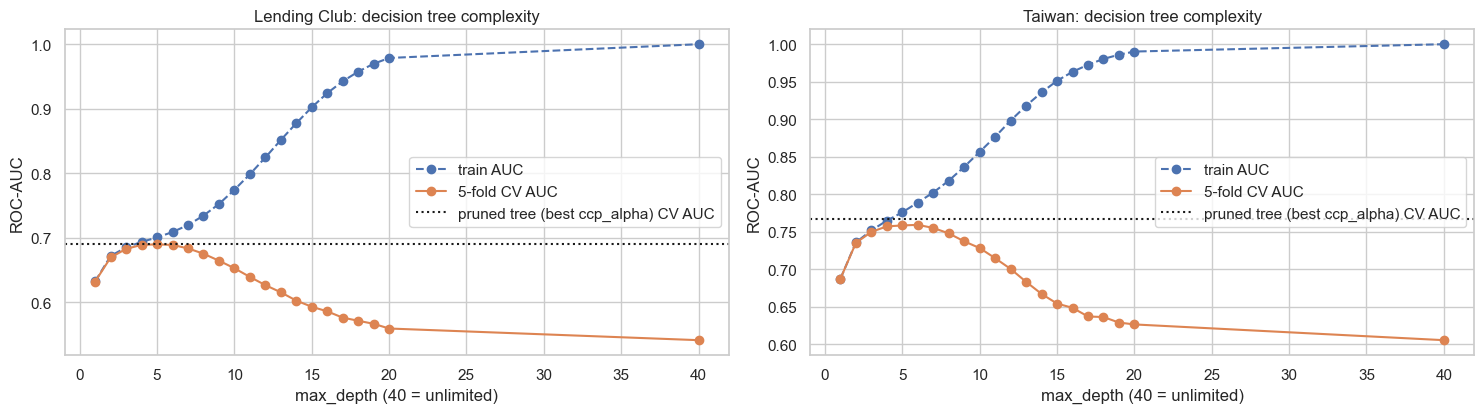

In [10]:
dt_best = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    prep = make_prep(num, cat).fit(Xa); Za = prep.transform(Xa)
    path = DecisionTreeClassifier(class_weight="balanced", random_state=SEED, min_samples_leaf=5).cost_complexity_pruning_path(Za, ya)
    alphas = np.logspace(-5, -2, 16)  # log-spaced so both lightly and heavily pruned trees are tried
    print(f"{name}: full pruning path has {len(path.ccp_alphas)} alphas (max {path.ccp_alphas.max():.2e}); searching 16 log-spaced values 1e-5..1e-2")
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED, min_samples_leaf=5))])
    gs = GridSearchCV(pipe, {"clf__ccp_alpha": alphas}, scoring="roc_auc", cv=CV5, n_jobs=-1).fit(Xa, ya)
    tree = gs.best_estimator_.named_steps["clf"]
    dt_best[name] = gs
    cvp = pd.DataFrame(gs.cv_results_)[["param_clf__ccp_alpha", "mean_test_score", "std_test_score"]]
    print("   CV AUC by ccp_alpha:", ", ".join(f"{a:.0e}:{m:.4f}" for a, m in zip(cvp.param_clf__ccp_alpha.astype(float), cvp.mean_test_score)))
    print(f"   best ccp_alpha={gs.best_params_['clf__ccp_alpha']:.2e} "
          f"CV AUC={gs.best_score_:.4f} | leaves={tree.get_n_leaves()} depth={tree.get_depth()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for ax, name in zip(axes, DATA):
    c = dt_curves[name]
    ax.plot(c.max_depth, c.train_auc, "o--", label="train AUC"); ax.plot(c.max_depth, c.cv_auc, "o-", label="5-fold CV AUC")
    ax.axhline(dt_best[name].best_score_, color="k", ls=":", label="pruned tree (best ccp_alpha) CV AUC")
    ax.set_xlabel("max_depth (40 = unlimited)"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"{name}: decision tree complexity"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_tree_depth.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Cost-complexity pruning
### What did we actually get?
* **Path sizes:** the full pruning path has 2,794 (Lending Club) and 1,372 (Taiwan) distinct α values.
* **Lending Club:**
  * CV AUC rises from **0.578 at α = 10⁻⁵** (barely pruned, overfit) to a **peak of 0.6907 at α = 2.5e-4** (0.00025), then falls to 0.632 at α = 10⁻².
  * The best tree has **24 leaves and depth 7**.
* **Taiwan:**
  * CV AUC goes 0.669 → **peak 0.7675 at α = 6.3e-4** → 0.690.
  * The best tree has **19 leaves and depth 8**.
* **Plot:** the dotted line (pruned tree) sits at or slightly above the best `max_depth` point on both datasets.
### How should we interpret the numbers?
* **Pruning works.** It produces a small tree (19–24 leaves) that matches or beats the best depth-limited tree: 0.6907 vs 0.6898 on Lending Club, and **0.7675 vs 0.7594** on Taiwan. Pruning can keep a deep branch where it helps and cut shallow branches elsewhere, which a single global `max_depth` cannot do.
* **The curve has an interior peak on both sides,** so the grid covered the right range.

## Cell 11 — A readable depth-3 tree for each dataset
### Why are we doing this?
The main business advantage of a single tree is that it can be read as rules. A depth-3 tree (at most 8 leaves) is shallow enough to explain to a credit committee, so we inspect which splits it chooses first.
### What should we examine after execution?
The root split (the single most informative feature/threshold), and the default rate in the riskiest and safest leaves.

Lending Club: root split = int_rate <= 14.395; depth-3 tree test AUC = 0.6887
Taiwan: root split = PAY_1 <= 1.500; depth-3 tree test AUC = 0.7234


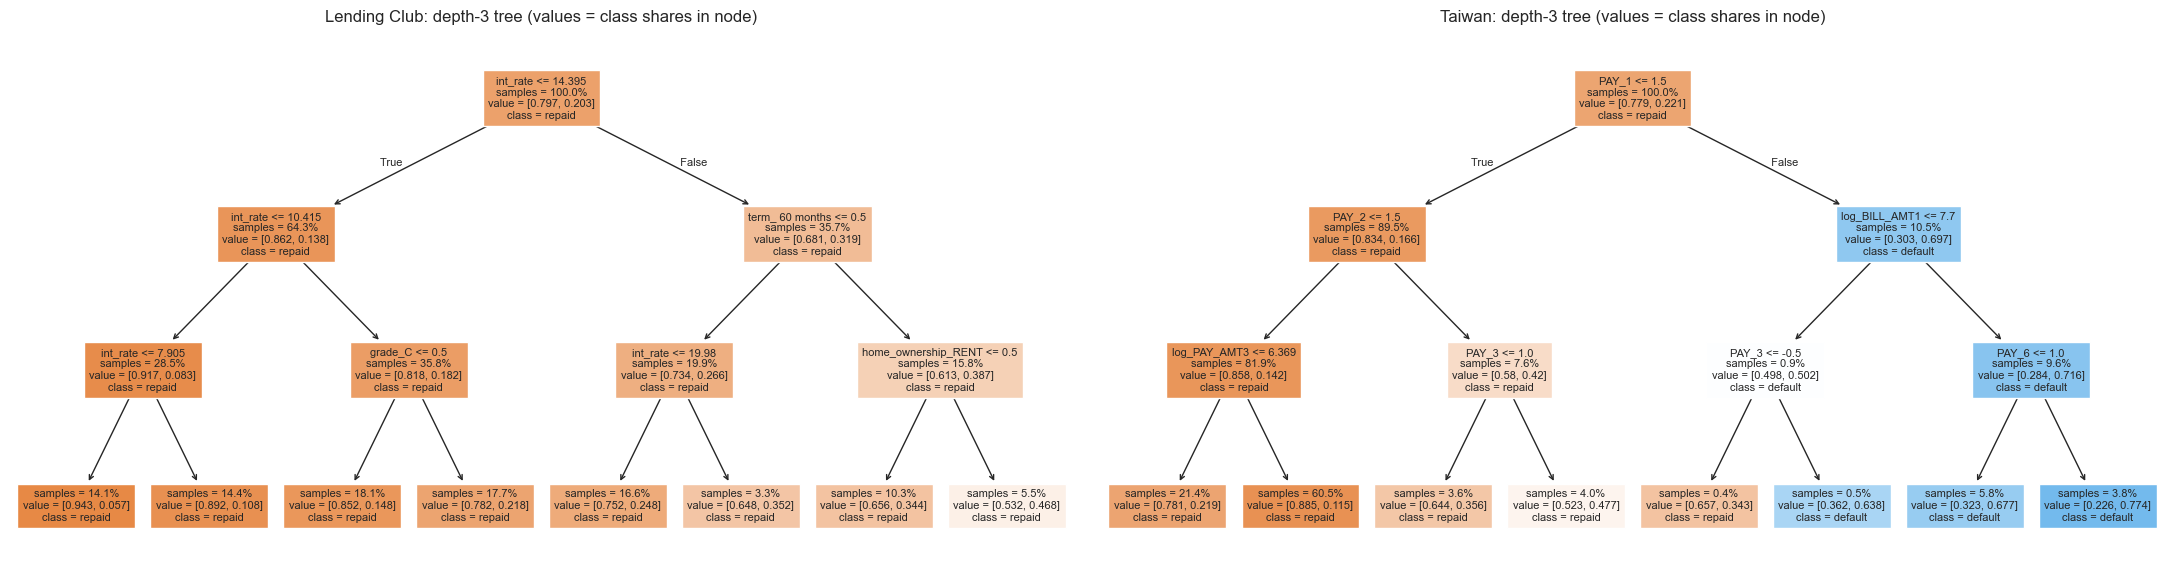

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(22, 6))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    prep = make_prep(num, cat, scale=False).fit(Xa)
    small = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(prep.transform(Xa), ya)
    fn = [f.replace("num__", "").replace("cat__", "") for f in prep.get_feature_names_out()]
    plot_tree(small, feature_names=fn, class_names=["repaid", "default"], filled=True, proportion=True, impurity=False, fontsize=8, ax=ax)
    ax.set_title(f"{name}: depth-3 tree (values = class shares in node)")
    Zb = prep.transform(Xb); leaf_auc = roc_auc_score(yb, small.predict_proba(Zb)[:, 1])
    print(f"{name}: root split = {fn[small.tree_.feature[0]]} <= {small.tree_.threshold[0]:.3f}; depth-3 tree test AUC = {leaf_auc:.4f}")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_tree_depth3.png", dpi=130, bbox_inches="tight"); plt.show()

## Result Interpretation — Depth-3 rule trees
### What did we actually get?
**Lending Club:**
* **Root split: `int_rate ≤ 14.395%`.** 64% of loans fall on the low-rate side, at about a 14% default rate; the 36% above it default at about 32%.
* The next splits are lower rate cut-offs on the left, and **`term = 60 months`** then **`home_ownership = RENT`** on the right. The riskiest leaf (high rate, 60-month term, renter, 5.5% of loans) defaults at about 47%.
* Test AUC of this 8-leaf tree: **0.6887**.

**Taiwan:**
* **Root split: `PAY_1 ≤ 1.5`.** The 10.5% of clients who are 2 or more months late on the latest bill default at about **70%**, compared with about 17% for everyone else.
* Further splits use `PAY_2`, the latest bill (`log_BILL_AMT1`) and older PAY months.
* Test AUC: **0.7234**.
### What does it mean?
* **Lending Club:** the interest rate, which already encodes the lender's grade, is the single strongest risk signal. Loan length and housing add to it.
* **Taiwan:** **recent delinquency dominates**, as the data-quality step suggested. A one-rule policy ("flag anyone 2+ months late") already isolates a group with about a 70% default rate.
* **For a credit committee:** a depth-3 tree reaches about 97% of the full tuned tree's AUC on both datasets (0.689 vs 0.701; 0.723 vs 0.755), with rules a committee can read.

## Cell 12 — Random forest: `RandomizedSearchCV` (DEPTH MODEL)
### Why are we doing this?
A random forest has several interacting hyperparameters, and a full grid would need hundreds of combinations × 5 folds.
`RandomizedSearchCV` samples 20 combinations from the ranges below. Research (Bergstra & Bengio, 2012) shows random search usually finds near-optimal settings far faster, because only a few hyperparameters really matter.
### What are we searching, and what does each mean?
| Hyperparameter | Values | What it controls |
|---|---|---|
| `n_estimators` | 150, 300 | number of trees; more = lower variance, diminishing returns |
| `max_depth` | 8, 12, 16, None | depth of each tree; the main bias–variance knob |
| `min_samples_leaf` | 5, 20, 50, 100 | smallest leaf; larger = smoother probabilities, less memorization |
| `max_features` | sqrt, 0.3 | features tried per split; smaller = more de-correlated trees |
| `class_weight` | balanced, balanced_subsample | reweights defaults (per forest or per bootstrap sample) |
* **Runtime:** a test fit with 600 trees, unlimited depth, 1-row leaves and 50% of features took over 5 minutes per fit. Those extreme settings are excluded here, and small leaves (down to 2) and deep trees (up to depth 24) are examined separately in the validation curves below.
### How does it work?
* Scoring is 5-fold stratified CV ROC-AUC on the **full** training set (48,000 / 23,972 rows).
* Trees run in parallel (`n_jobs=-1`).
* `return_train_score=True` records the train–validation gap.
### What should we examine after execution?
* The best hyperparameters and the CV AUC ± SD.
* How the top candidates differ.
* The train–CV gap of the best model compared with the worst-overfitting candidate.

In [12]:
rf_space = {"clf__n_estimators": [150, 300], "clf__max_depth": [8, 12, 16, None],
            "clf__min_samples_leaf": [5, 20, 50, 100], "clf__max_features": ["sqrt", 0.3],
            "clf__class_weight": ["balanced", "balanced_subsample"]}
rf_rs = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))])
    t0 = time.time()
    rs = RandomizedSearchCV(pipe, rf_space, n_iter=20, scoring="roc_auc", cv=CV5, n_jobs=-1, random_state=SEED,
                            return_train_score=True).fit(Xa, ya)
    rf_rs[name] = rs
    r = pd.DataFrame(rs.cv_results_); r["gap"] = r.mean_train_score - r.mean_test_score
    cols = ["param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__max_features",
            "param_clf__class_weight", "mean_train_score", "mean_test_score", "std_test_score", "gap"]
    print(f"\n{name}: search {time.time()-t0:.0f}s | BEST {rs.best_params_} | CV AUC {rs.best_score_:.4f} +- {r.loc[rs.best_index_, 'std_test_score']:.4f}")
    display(r.sort_values("rank_test_score")[cols].head(5).round(4))
    print("Largest train-CV gaps:"); display(r.sort_values("gap", ascending=False)[cols].head(2).round(4))


Lending Club: search 41s | BEST {'clf__n_estimators': 300, 'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': 12, 'clf__class_weight': 'balanced'} | CV AUC 0.7047 +- 0.0049


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
2,300,12,20,sqrt,balanced,0.7652,0.7047,0.0049,0.0605
18,300,None,50,0.3,balanced_subsample,0.7687,0.7042,0.0049,0.0645
4,150,16,20,sqrt,balanced_subsample,0.7921,0.7042,0.0051,0.0879
10,150,12,100,0.3,balanced_subsample,0.7355,0.7041,0.0051,0.0314
3,300,12,100,0.3,balanced,0.7325,0.7041,0.0049,0.0283


Largest train-CV gaps:


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
5,150,None,5,0.3,balanced,0.9842,0.6967,0.0042,0.2875
15,300,None,5,sqrt,balanced_subsample,0.9492,0.7011,0.0045,0.2481



Taiwan: search 37s | BEST {'clf__n_estimators': 300, 'clf__min_samples_leaf': 50, 'clf__max_features': 0.3, 'clf__max_depth': None, 'clf__class_weight': 'balanced_subsample'} | CV AUC 0.7864 +- 0.0077


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
18,300,None,50,0.3,balanced_subsample,0.8481,0.7864,0.0077,0.0617
2,300,12,20,sqrt,balanced,0.8593,0.7856,0.0085,0.0737
11,300,12,20,0.3,balanced,0.8655,0.7856,0.0082,0.0799
16,150,16,50,sqrt,balanced,0.8366,0.7854,0.0083,0.0512
9,150,12,20,0.3,balanced,0.8650,0.7854,0.0081,0.0796


Largest train-CV gaps:


,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__max_features,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,gap
5,150,None,5,0.3,balanced,0.9793,0.7791,0.0084,0.2002
15,300,None,5,sqrt,balanced_subsample,0.9714,0.7804,0.0079,0.1910


## Result Interpretation — Random forest random search (DEPTH MODEL)
### What did we actually get?
**Lending Club (41 s):**
* **Best: 300 trees, `max_depth = 12`, `min_samples_leaf = 20`, `max_features = sqrt`, `class_weight = balanced`, with CV AUC 0.7047 ± 0.0049.**
* The top 5 candidates fall between 0.7041 and 0.7047 (well within one SD) despite quite different settings.
* Train–CV gap of the best model: 0.061.
* **Most overfit:** unlimited depth with 5-row leaves, at **train 0.984 vs CV 0.697** (gap 0.29).

**Taiwan (37 s):**
* **Best: 300 trees, `max_depth = None`, `min_samples_leaf = 50`, `max_features = 0.3`, `class_weight = balanced_subsample`, with CV AUC 0.7864 ± 0.0077.**
* The top 5 span 0.7854–0.7864. Gap of the best model: 0.062.
* **Most overfit:** unlimited depth with 5-row leaves, at train 0.979 vs CV 0.779 (gap 0.20).
### How should we interpret the numbers?
* **The winners are regularized in different ways.** On Lending Club it is the depth limit (12) plus 20-row leaves; on Taiwan it is large leaves (50) with unlimited depth. Both stop individual trees from memorizing.
* **Averaging protects against overfitting.** Even the most overfit forest loses only about 0.008 AUC on CV relative to the best, whereas a single unlimited tree lost about 0.15. This is the core benefit of bagging and random feature subsets.
* **Taiwan improves on every earlier model, with no gain on Lending Club:**
  * Taiwan CV AUC **0.786**, against logistic regression 0.752, the best SVM 0.762 and the pruned tree 0.768.
  * Lending Club's 0.705 is level with logistic regression (0.703).

## Cell 13 — Depth analysis: validation curves for `min_samples_leaf` and `max_depth`, plus OOB
### Why are we doing this?
Random search tells us *which* setting wins; validation curves tell us *why*. Holding the other best parameters fixed, we vary one
knob at a time and plot train vs CV AUC. We also refit the best forest with `oob_score=True` to compare the out-of-bag estimate with the CV estimate.
### What should we examine after execution?
* Where each curve peaks, and how fast the gap opens as leaves get smaller or trees deeper.
* Whether OOB AUC agrees with the CV AUC.

Lending Club min_samples_leaf: best 20 CV 0.7045 (train 0.7644) | at 2: train 0.8319 CV 0.7030


Lending Club max_depth: best 12 CV 0.7045 (train 0.7644) | at 2: train 0.6916 CV 0.6894


Lending Club: OOB AUC 0.7029 vs 5-fold CV AUC 0.7047


Taiwan min_samples_leaf: best 50 CV 0.7859 (train 0.8476) | at 2: train 0.9990 CV 0.7735


Taiwan max_depth: best 24 CV 0.7859 (train 0.8476) | at 2: train 0.7691 CV 0.7669


Taiwan: OOB AUC 0.7864 vs 5-fold CV AUC 0.7864


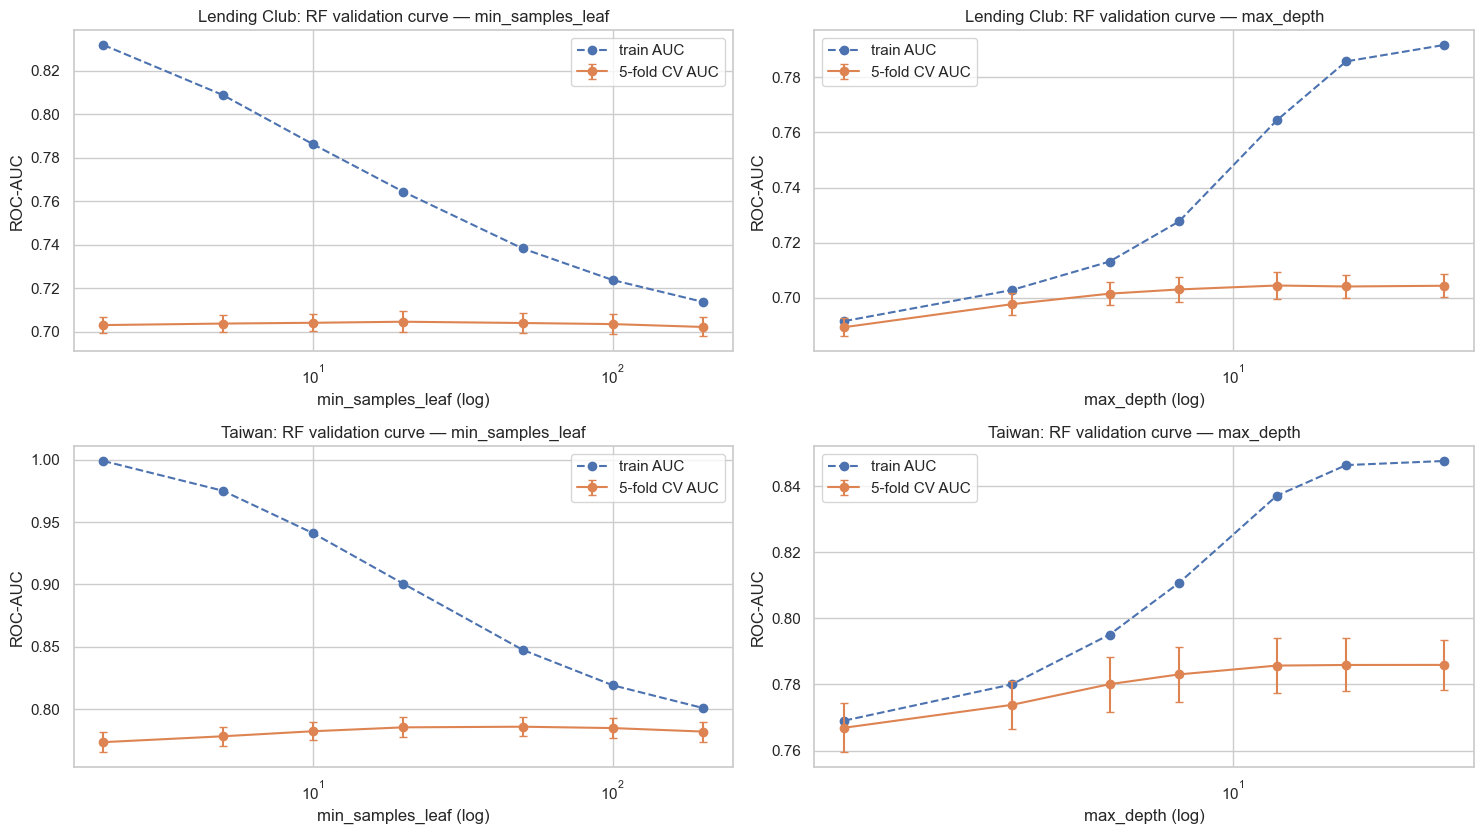

In [13]:
from sklearn.model_selection import validation_curve
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
rf_oob = {}
for row, (name, (Xa, Xb, ya, yb, num, cat)) in enumerate(DATA.items()):
    best = rf_rs[name].best_estimator_
    base = Pipeline([("prep", make_prep(num, cat)), ("clf", RandomForestClassifier(**{**best.named_steps["clf"].get_params(), "n_estimators": 150, "n_jobs": 1}))])
    for col, (pname, vals, lab) in enumerate([("clf__min_samples_leaf", [2, 5, 10, 20, 50, 100, 200], "min_samples_leaf"),
                                              ("clf__max_depth", [2, 4, 6, 8, 12, 16, 24], "max_depth")]):
        tr, va = validation_curve(base, Xa, ya, param_name=pname, param_range=vals, cv=CV5, scoring="roc_auc", n_jobs=-1)
        ax = axes[row, col]
        ax.plot(vals, tr.mean(1), "o--", label="train AUC"); ax.errorbar(vals, va.mean(1), yerr=va.std(1), fmt="o-", capsize=3, label="5-fold CV AUC")
        ax.set_xscale("log"); ax.set_xlabel(lab + " (log)"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"{name}: RF validation curve — {lab}"); ax.legend()
        i = int(np.argmax(va.mean(1)))
        print(f"{name} {lab}: best {vals[i]} CV {va.mean(1)[i]:.4f} (train {tr.mean(1)[i]:.4f}) | at {vals[0]}: train {tr.mean(1)[0]:.4f} CV {va.mean(1)[0]:.4f}")
    oob = RandomForestClassifier(**{**best.named_steps["clf"].get_params(), "oob_score": True, "n_jobs": -1})
    Za = make_prep(num, cat).fit(Xa).transform(Xa)
    oob.fit(Za, ya); rf_oob[name] = roc_auc_score(ya, oob.oob_decision_function_[:, 1])
    print(f"{name}: OOB AUC {rf_oob[name]:.4f} vs 5-fold CV AUC {rf_rs[name].best_score_:.4f}")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_rf_validation.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Validation curves and OOB (DEPTH MODEL)
### What did we actually get?
**`min_samples_leaf` (left panels):**
* As leaves shrink to 2, train AUC rises to **0.832 (Lending Club)** and **0.999 (Taiwan)**.
* CV AUC stays almost flat: Lending Club 0.703–0.705, peaking at 20; Taiwan 0.774–0.786, peaking at 50.

**`max_depth` (right panels):**
* At depth 2, CV AUC is 0.689 / 0.767 (underfit).
* It rises to a plateau from about depth 8–12 onward: Lending Club best at 12 (0.7045), Taiwan best at 24 (0.7859), essentially flat after depth 12.
* Train AUC keeps rising (0.79 / 0.85).

**OOB vs CV:**
* Lending Club: OOB **0.7029** vs CV 0.7047.
* Taiwan: OOB **0.7864** vs CV 0.7864.
### How should we interpret the numbers?
* **Bias–variance reading:**
  * The **bias** side is visible only at very shallow depth.
  * The **variance** side shows up as the widening train–CV gap, but the forest's averaging stops that gap from damaging validation performance much. That is why random forests are forgiving to tune.
  * Taiwan gains about 0.012 AUC from larger leaves, because its smaller sample is noisier per leaf.
* **OOB works as a free validation set.** It agrees with 5-fold CV to within 0.002, so a forest's generalization can be checked without a holdout, using the 37% of rows each tree never saw.
* **Plot:** the CV error bars (±1 SD across folds) overlap across most of each plateau. Any setting in the plateau is statistically equivalent.

## Cell 14 — Feature importance: impurity-based vs permutation (test set)
### Why are we doing this?
* **Impurity importance** is the total Gini decrease contributed by each feature across all trees. It is fast, but biased toward continuous or high-cardinality features, which offer more possible split points.
* **Permutation importance** is the drop in **test** AUC when one feature's values are shuffled. It is slower but measures real predictive reliance on unseen data, and it is computed on the *original* columns, so a categorical variable is scored as a whole.
Comparing the two guards against over-reading either one.
### What should we examine after execution?
The top features under each method, where they agree or disagree, and how the rankings relate to the EDA (grade and int_rate for Lending Club; PAY_1 for Taiwan).


Lending Club — top 8 impurity importance:
int_rate           0.3398
term_ 60 months    0.1075
dti                0.0962
log_annual_inc     0.0637
revol_util         0.0584
loan_amnt          0.0569
grade_B            0.0450
grade_E            0.0385
Lending Club — top 8 permutation importance (mean test-AUC drop +- sd):
                auc_drop      sd
int_rate          0.0684  0.0038
grade             0.0178  0.0010
term              0.0121  0.0007
dti               0.0060  0.0018
home_ownership    0.0049  0.0002
log_annual_inc    0.0035  0.0006
loan_amnt         0.0028  0.0006
purpose           0.0007  0.0004



Taiwan — top 8 impurity importance:
PAY_1            0.2942
PAY_2            0.1151
PAY_3            0.0691
PAY_4            0.0543
log_LIMIT_BAL    0.0449
log_BILL_AMT1    0.0432
log_PAY_AMT1     0.0425
log_PAY_AMT2     0.0378
Taiwan — top 8 permutation importance (mean test-AUC drop +- sd):
               auc_drop      sd
PAY_1            0.0759  0.0059
log_LIMIT_BAL    0.0188  0.0013
PAY_2            0.0090  0.0015
log_BILL_AMT1    0.0061  0.0011
PAY_4            0.0055  0.0010
PAY_3            0.0054  0.0005
PAY_5            0.0031  0.0008
PAY_6            0.0029  0.0005


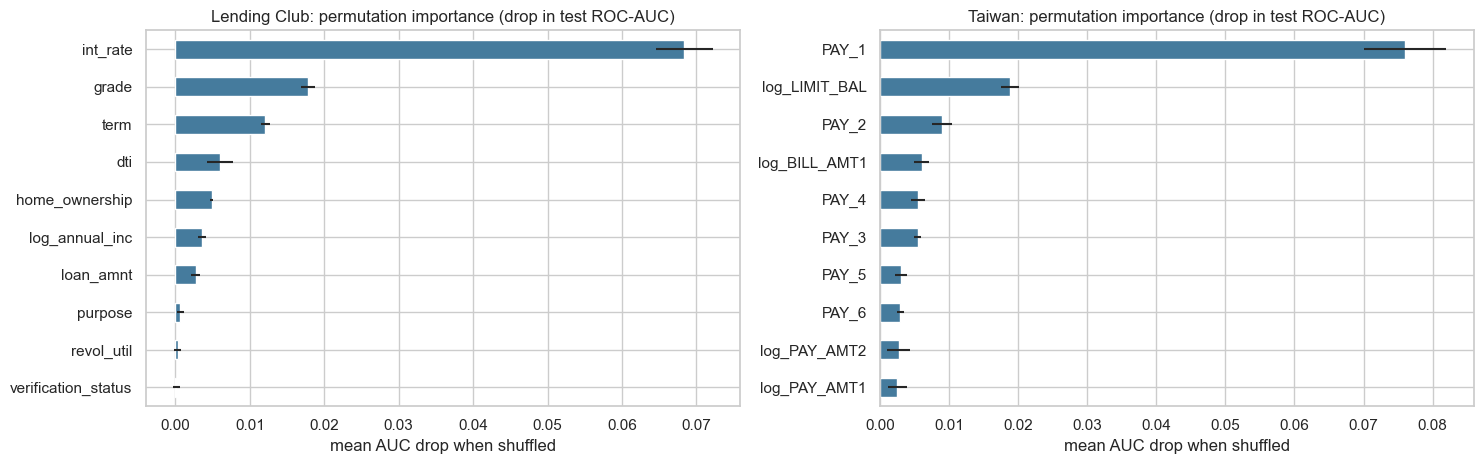

In [14]:
imp = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    best = rf_rs[name].best_estimator_
    names = [f.replace("num__", "").replace("cat__", "") for f in best.named_steps["prep"].get_feature_names_out()]
    gini = pd.Series(best.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
    pi = permutation_importance(best, Xb, yb, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
    perm = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False)
    imp[name] = (gini, perm, pd.Series(pi.importances_std, index=Xb.columns))
    print(f"\n{name} — top 8 impurity importance:"); print(gini.head(8).round(4).to_string())
    print(f"{name} — top 8 permutation importance (mean test-AUC drop +- sd):")
    print(pd.DataFrame({"auc_drop": perm.head(8), "sd": imp[name][2][perm.head(8).index]}).round(4).to_string())
    perm.head(10)[::-1].plot.barh(ax=ax, xerr=imp[name][2][perm.head(10).index[::-1]], color="#457b9d")
    ax.set_title(f"{name}: permutation importance (drop in test ROC-AUC)"); ax.set_xlabel("mean AUC drop when shuffled")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_rf_importance.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Feature importance (DEPTH MODEL)
### What did we actually get?
**Lending Club:**
* **Impurity importance:** `int_rate` 0.340, `term_60` 0.108, `dti` 0.096, `log_annual_inc` 0.064, `revol_util` 0.058, `loan_amnt` 0.057, then grade dummies.
* **Permutation importance (test AUC drop):**
  * **`int_rate` 0.068 ± 0.004**
  * `grade` 0.018
  * `term` 0.012
  * `dti` 0.006
  * `home_ownership` 0.005
  * `log_annual_inc` 0.004
  * `loan_amnt` 0.003
  * `purpose` 0.001

**Taiwan:**
* **Impurity importance:** **`PAY_1` 0.294**, `PAY_2` 0.115, `PAY_3` 0.069, `PAY_4` 0.054, `log_LIMIT_BAL` 0.045, `log_BILL_AMT1` 0.043.
* **Permutation importance:**
  * **`PAY_1` 0.076 ± 0.006**
  * `log_LIMIT_BAL` 0.019
  * `PAY_2` 0.009
  * `log_BILL_AMT1` 0.006
  * `PAY_3`–`PAY_6` 0.003–0.006
### How should we interpret the numbers?
* **The two methods agree on the leader.** `int_rate` and `PAY_1` are first under both, and by a wide margin: shuffling either one alone costs about 0.07 AUC.
* **They disagree on the second tier, as theory predicts:**
  * **Impurity inflates continuous features.** It ranks `dti`, income and `revol_util` above `grade`, because continuous features offer many split points. Permutation (on held-out data, scoring grade as a whole) puts **grade and term ahead of them**.
  * **Correlated features share credit.** On Taiwan, impurity spreads importance over `PAY_2`–`PAY_4`. Permutation shows that once `PAY_1` is known the older months add little, because a correlated feature can stand in when one is shuffled. This is the Week 3 collinearity finding showing up again.
  * **`log_LIMIT_BAL` rises to #2 under permutation.** The bank's own limit decision carries risk information, as Week 1 found.
* **Domain reading:**
  * **Lending Club:** risk is mostly *priced* (`int_rate` and grade are Lending Club's own risk assessment), and loan structure (`term`) is second.
  * **Taiwan:** risk is mostly *behavioural*. The most recent repayment status is the strongest early-warning signal.
### What can we NOT conclude?
* **Causation:** a high rate does not *cause* default. Partly the reverse holds, since riskier borrowers are priced higher, although high payments may add some burden. These are measures of predictive reliance within this model.

## Cell 15 — Threshold choice for the forest (out-of-fold) and held-out test metrics
### Why are we doing this?
This is the same discipline as Week 4. The decision threshold is chosen to maximize F1 on **out-of-fold** training predictions, then applied once to the test set.
### What should we examine after execution?
The chosen threshold, and test ROC-AUC, PR-AUC, precision, recall and F1 at 0.5 compared with the tuned cutoff.

In [15]:
rf_test = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    best = rf_rs[name].best_estimator_
    oof = cross_val_predict(best, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof); f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    thr = float(th[np.argmax(f1s)]); prob = best.predict_proba(Xb)[:, 1]
    rf_test[name] = (prob, thr)
    print(f"\n{name}: OOF F1-optimal threshold {thr:.3f}")
    display(pd.DataFrame({"at 0.5": scores(yb, prob, 0.5), f"at {thr:.3f}": scores(yb, prob, thr)}).T.round(4))
    print("Confusion matrix at tuned threshold [[TN FP] [FN TP]]:", confusion_matrix(yb, (prob >= thr).astype(int)).tolist())


Lending Club: OOF F1-optimal threshold 0.495


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.6480,0.3216,0.6620,0.4329,0.7099,0.3801,0.5000
at 0.495,0.6422,0.3191,0.6735,0.4331,0.7099,0.3801,0.4952


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[6066, 3499], [795, 1640]]



Taiwan: OOF F1-optimal threshold 0.543


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.7686,0.4814,0.5950,0.5322,0.7733,0.5507,0.5000
at 0.543,0.7837,0.5104,0.5535,0.5311,0.7733,0.5507,0.5428


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[3963, 704], [592, 734]]


## Result Interpretation — Random forest on the held-out test set (DEPTH MODEL)
### What did we actually get?
**Lending Club:**
* **Test ROC-AUC 0.7099, PR-AUC 0.3801.** The out-of-fold threshold is **0.495**.
* At that threshold: precision 0.319, recall **0.674**, F1 0.433.
* Confusion matrix: TN 6,066, FP 3,499, FN 795, TP 1,640.

**Taiwan:**
* **Test ROC-AUC 0.7733, PR-AUC 0.5507.** The threshold is **0.543**.
* At that threshold: precision 0.510, recall 0.554, **F1 0.531**, accuracy 0.784.
* Confusion matrix: TN 3,963, FP 704, FN 592, TP 734.
### How should we interpret the numbers?
* **The test scores sit close to the CV estimates.** Lending Club tests at 0.710 against CV 0.705, and Taiwan at 0.773 against CV 0.786. The Taiwan drop of 0.013 is within about 1.7 fold-SDs, so the tuning did not overfit the validation folds.
* **Taiwan PR-AUC of 0.551 is 2.5× the random baseline (0.221),** the best of any model so far.
* **Threshold:** as in Week 4, balanced class weights already put the F1 optimum near 0.5, so moving the cutoff changes the precision/recall mix rather than F1.

## Cell 16 — Final model comparison on the shared test sets (Weeks 4, 5, 6)
### Why are we doing this?
This is the table the Milestone One report is built on. Every model is refit here on the identical split, so the comparison is apples to apples:
* **LogReg:** balanced class weights, with the best C and penalty from Week 4's grid.
* **SVM:** Week 5's best kernel, C and γ, on the 6,000-row stratified subsample.
* **Decision tree:** pruned with the best `ccp_alpha`.
* **Random forest:** the best settings from the random search.
Thresholds are chosen on out-of-fold training predictions for LogReg, DT and RF. The SVM uses its own boundary (score 0).
### What should we examine after execution?
* ROC-AUC and PR-AUC, which are threshold-free, against the baselines (0.5 and the default rate).
* F1 and recall at each model's threshold.
* The ROC and PR curves.

,dataset,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,Lending Club,Logistic regression (W4),0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098
1,Lending Club,"Decision tree, pruned (W6)",0.6060,0.3009,0.7113,0.4229,0.7006,0.3531,0.4604
2,Lending Club,"Random forest, tuned (W6)",0.6422,0.3191,0.6735,0.4331,0.7099,0.3801,0.4952
3,Lending Club,"RBF SVM, tuned (W5, 6k rows)",0.6769,0.3357,0.6049,0.4318,0.7014,0.3627,0.0000
4,Taiwan,Logistic regression (W4),0.7586,0.4629,0.5694,0.5107,0.7410,0.4993,0.5396
5,Taiwan,"Decision tree, pruned (W6)",0.7724,0.4872,0.5460,0.5149,0.7545,0.4923,0.5756
6,Taiwan,"Random forest, tuned (W6)",0.7837,0.5104,0.5535,0.5311,0.7733,0.5507,0.5428
7,Taiwan,"RBF SVM, tuned (W5, 6k rows)",0.7492,0.4496,0.5950,0.5122,0.7443,0.4890,0.0000


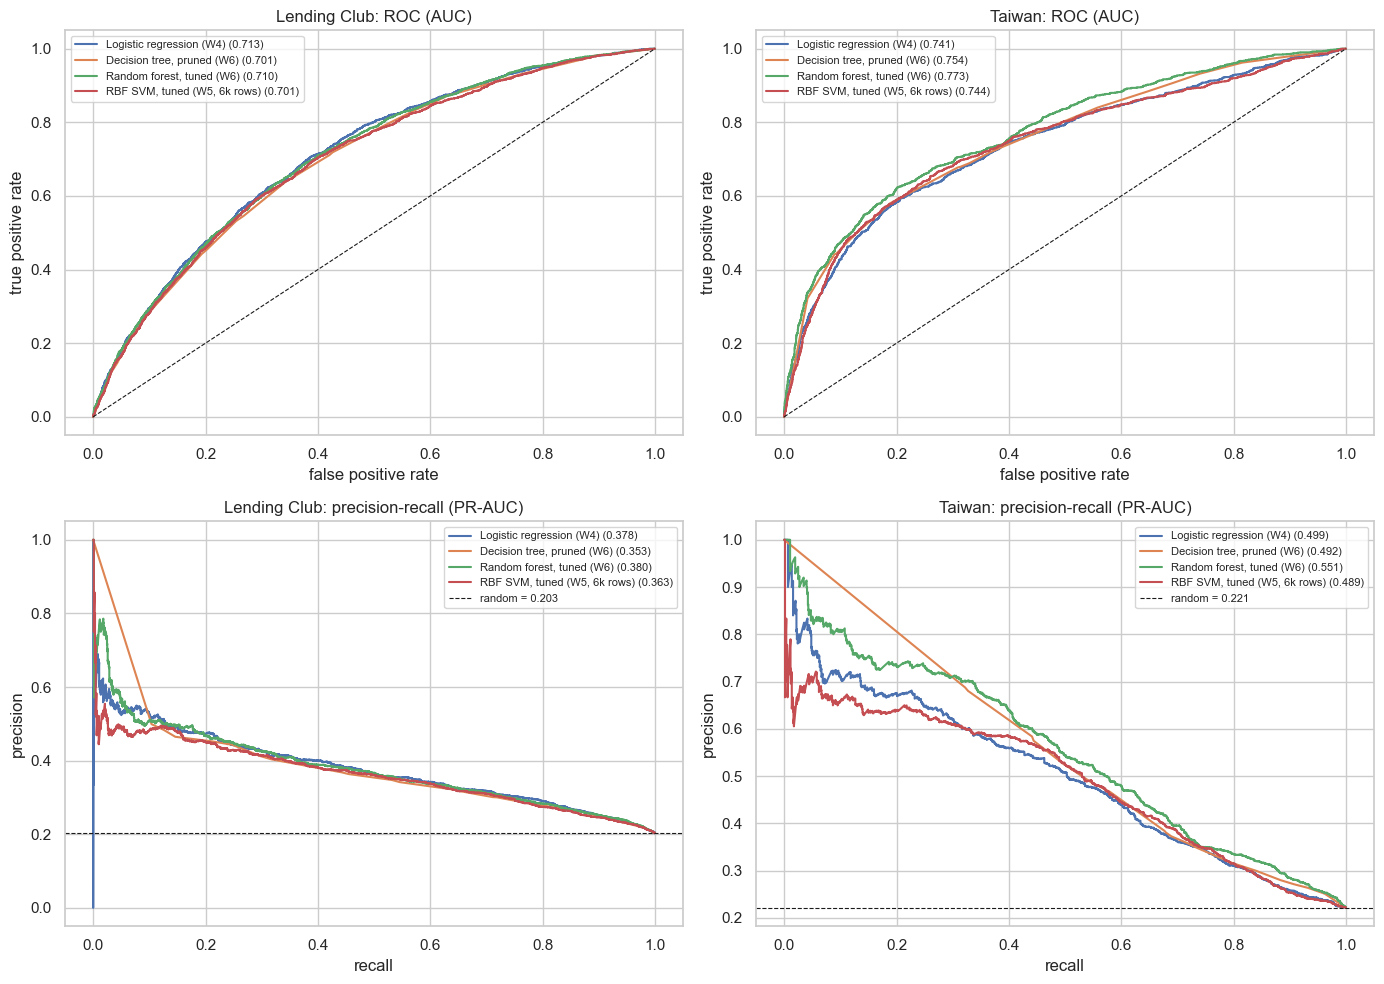

In [16]:
W4_BEST = {"Lending Club": {"C": 1, "penalty": "l1"}, "Taiwan": {"C": 0.001, "penalty": "l2"}}
W5_BEST = {"Lending Club": {"kernel": "rbf", "C": 0.1, "gamma": 0.01}, "Taiwan": {"kernel": "rbf", "C": 1, "gamma": 0.01}}
def oof_thr(est, Xa, ya):
    oof = cross_val_predict(est, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof); f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    return float(th[np.argmax(f1s)])
final_rows, curves = [], {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    lr = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000, **W4_BEST[name]))]).fit(Xa, ya)
    Xs, _, ys, _ = train_test_split(Xa, ya, train_size=6000, stratify=ya, random_state=SEED)
    svm = Pipeline([("prep", make_prep(num, cat)), ("clf", SVC(class_weight="balanced", **W5_BEST[name]))]).fit(Xs, ys)
    dt = dt_best[name].best_estimator_; rf = rf_rs[name].best_estimator_
    models = {"Logistic regression (W4)": (lr, oof_thr(lr, Xa, ya)), "Decision tree, pruned (W6)": (dt, oof_thr(dt, Xa, ya)),
              "Random forest, tuned (W6)": (rf, rf_test[name][1])}
    curves[name] = {}
    for mname, (m, thr) in models.items():
        prob = m.predict_proba(Xb)[:, 1]; curves[name][mname] = prob
        final_rows.append({"dataset": name, "model": mname, **scores(yb, prob, thr)})
    sc = svm.decision_function(Xb); pred = (sc >= 0).astype(int); curves[name]["RBF SVM, tuned (W5, 6k rows)"] = sc
    final_rows.append({"dataset": name, "model": "RBF SVM, tuned (W5, 6k rows)", "accuracy": accuracy_score(yb, pred), "precision": precision_score(yb, pred),
                       "recall": recall_score(yb, pred), "f1": f1_score(yb, pred), "roc_auc": roc_auc_score(yb, sc),
                       "pr_auc": average_precision_score(yb, sc), "threshold": 0.0})
final = pd.DataFrame(final_rows)
display(final.round(4))
final.round(4).to_csv(f"{FIG}/table_final_model_comparison.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, (name, (Xa, Xb, ya, yb, num, cat)) in enumerate(DATA.items()):
    for mname, s in curves[name].items():
        f_, t_, _ = roc_curve(yb, s); axes[0, col].plot(f_, t_, label=f"{mname} ({roc_auc_score(yb, s):.3f})")
        p_, r_, _ = precision_recall_curve(yb, s); axes[1, col].plot(r_, p_, label=f"{mname} ({average_precision_score(yb, s):.3f})")
    axes[0, col].plot([0, 1], [0, 1], "k--", lw=.8); axes[0, col].set(xlabel="false positive rate", ylabel="true positive rate", title=f"{name}: ROC (AUC)")
    axes[1, col].axhline(yb.mean(), color="k", ls="--", lw=.8, label=f"random = {yb.mean():.3f}")
    axes[1, col].set(xlabel="recall", ylabel="precision", title=f"{name}: precision-recall (PR-AUC)")
    axes[0, col].legend(fontsize=8); axes[1, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w6_roc_pr_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

## Result Interpretation — Final cross-model comparison (Weeks 4–6)
### What did we actually get?
| Dataset | Model | ROC-AUC | PR-AUC | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|---|---|---|
| Lending Club | Logistic regression | **0.7126** | 0.3782 | 0.324 | 0.653 | 0.433 | 0.653 |
| Lending Club | Decision tree (pruned) | 0.7006 | 0.3531 | 0.301 | **0.711** | 0.423 | 0.606 |
| Lending Club | **Random forest** | 0.7099 | **0.3801** | 0.319 | 0.674 | **0.433** | 0.642 |
| Lending Club | RBF SVM (6k rows) | 0.7014 | 0.3627 | **0.336** | 0.605 | 0.432 | **0.677** |
| Taiwan | Logistic regression | 0.7410 | 0.4993 | 0.463 | 0.569 | 0.511 | 0.759 |
| Taiwan | Decision tree (pruned) | 0.7545 | 0.4923 | 0.487 | 0.546 | 0.515 | 0.772 |
| Taiwan | **Random forest** | **0.7733** | **0.5507** | **0.510** | 0.554 | **0.531** | **0.784** |
| Taiwan | RBF SVM (6k rows) | 0.7443 | 0.4890 | 0.450 | **0.595** | 0.512 | 0.749 |

**ROC and PR curves:** on Lending Club the four ROC curves nearly overlap. On Taiwan the random-forest curve sits visibly above the others at low false-positive rates, and its PR curve is highest across most recall levels.
### How should we interpret the numbers?
* **Taiwan: the random forest wins clearly.**
  * It leads on every threshold-free metric: **+0.032 ROC-AUC and +0.051 PR-AUC over logistic regression**, and +0.019 AUC over the pruned tree.
  * The data have threshold and interaction structure (`PAY_1 ≥ 2`, bill × payment status) that the forest captures and a linear model cannot.
* **Lending Club: a four-way tie.**
  * All models fall within **0.011 AUC** (0.701–0.713), and the F1 scores are within 0.01.
  * Logistic regression is marginally best on ROC-AUC, the forest marginally best on PR-AUC.
  * The available application features carry a roughly linear signal (much of it already summarized in `int_rate` and grade), so model flexibility has nothing extra to find.
* **No model is uniformly best on accuracy, precision and recall.** Those depend on the threshold. ROC-AUC and PR-AUC are the fair comparison, and the cost of each error type should drive the final cutoff.
### What can we conclude?
* **Depth model choice is justified.** The **random forest** is the strongest or tied-strongest model on both datasets. Logistic regression stays the interpretable baseline, and is the practical choice on Lending Club given equal accuracy.
* **Generalization lesson:** the gain from nonlinear models depends on the data. It is large where behaviour has threshold effects (Taiwan's repayment history) and nil where the risk signal is already priced in (Lending Club's rate and grade).
### What can we NOT conclude?
* **Calibration:** none of these probabilities have been checked for calibration (whether 30% predicted means 30% observed). That is needed before using them in loss forecasting.
* **Time stability:** the Lending Club split is random, not by date, so performance over time has not been checked.